# Search-09b — Minima fallacieux et relaxation SDP factorisée

**Navigation** : [Partie 1](README.md) | [Version Python](Search-09b-SpuriousMinima.ipynb) | [Search-09c — discrépance](Search-09c-CombinatorialDiscrepancy.ipynb)

**Objectifs** : comparer MaxCut exhaustif à une relaxation SDP, piloter une ascension riemannienne factorisée, explorer des départs et interpréter les limites des tests de perturbation. **Prérequis** : matrices symétriques, optimisation convexe, gradients et MaxCut. **Durée estimée** : 90 minutes.

CVXPY et CLARABEL donnent une **référence conique numérique** via Python.NET ; l'énumération et l'ascension sont pilotées en C#. Les tests de perturbation ne certifient pas un maximum local.

In [1]:
// Le pont appelle les vrais moteurs NumPy et CVXPY/CLARABEL pour les fixtures et la référence SDP.
// Le recensement et les coupes combinatoires sont calculés ensuite en C#.
#r "nuget: pythonnet, 3.1.0"
#load "../../Config/PythonNetLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text.Json;
using System.Globalization;
using Python.Runtime;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "cvxpy");
PyModule py;
using (Py.GIL())
{
    py = Py.CreateScope();
    py.Exec(@"import json, numpy as np, cvxpy as cp, clarabel

def versions(): return f'numpy {np.__version__} ; cvxpy {cp.__version__} ; clarabel {clarabel.__version__}'
def fixture(k):
 n=[6,8,10][k]; W=np.zeros((n,n))
 if k==0:
  for i in range(n): W[i,(i+1)%n]=W[(i+1)%n,i]=1
 elif k==1:
  a=np.random.default_rng(42).uniform(.1,1.,(n,n));W=np.triu(a,1)+np.triu(a,1).T
 else:
  a=(np.random.default_rng(7).random((n,n))<.5).astype(float);W=np.triu(a,1)+np.triu(a,1).T
 return json.dumps(W.tolist())
def normals(n,r,k,seed): return json.dumps(np.random.default_rng(seed).standard_normal((k,n,r)).tolist())
def sdp(js):
 W=np.array(json.loads(js)); n=len(W); Y=cp.Variable((n,n),PSD=True); p=cp.Problem(cp.Maximize(.25*cp.sum(cp.multiply(W,1-Y))),[cp.diag(Y)==1]);p.solve(solver=cp.CLARABEL)
 if p.status not in ('optimal','optimal_inaccurate'): raise RuntimeError(f'CLARABEL: {p.status}')
 return json.dumps([float(p.value),p.status])");
    Console.WriteLine(py.Get("versions").Invoke().As<string>());
}

Console.WriteLine($"Runtime {System.Runtime.InteropServices.RuntimeInformation.FrameworkDescription} ; pont Python.NET ciblé sur NumPy et CLARABEL");


The below script needs to be able to find the current output cell; this is an easy method to get it.

Installed Packages pythonnet, 3.1.0

numpy 2.5.2 ; cvxpy 1.9.2 ; clarabel 0.11.1


Runtime .NET 10.0.15 ; pont Python.NET ciblé sur NumPy et CLARABEL


## A. MaxCut et SDP

Pour $W$ symétrique, $\operatorname{cut}(s)=\frac12\sum_{i<j}W_{ij}(1-s_i s_j)$. La relaxation remplace $s_is_j$ par $Y_{ij}$ avec $Y\succeq0$ et $\operatorname{diag}(Y)=1$. Nous utilisons les mêmes matrices NumPy que le Python : cycle $C_6$, $K_8$ pondéré graine 42 et $G(10,0{,}5)$ graine 7.

In [2]:
// Les matrices sont désérialisées sans modifier les valeurs numériques.
// Comparer la relaxation convexe à une énumération exacte distingue SDP et coupe entière.
string PyString(string name, params PyObject[] args)
{
    using (Py.GIL())
    {
        using var f = py.Get(name);
        using var tuple = new PyTuple(args);
        using var result = f.Invoke(tuple);
        return result.As<string>();
    }
}

double[, ] Matrice(string json)
{
    var a = JsonSerializer.Deserialize<double[][]>(json);
    int m = a.Length, n = a[0].Length;
    var z = new double[m, n];
    for (int i = 0; i < m; i++)
        for (int j = 0; j < n; j++)
            z[i, j] = a[i][j];
    return z;
}

string JsonMatrice(double[, ] a) => JsonSerializer.Serialize(Enumerable.Range(0, a.GetLength(0)).Select(i => Enumerable.Range(0, a.GetLength(1)).Select(j => a[i, j]).ToArray()).ToArray());
double[, ] Fixture(int i) => Matrice(PyString("fixture", i.ToPython()));
double[,, ] Normales(int n, int r, int k, int seed)
{
    var a = JsonSerializer.Deserialize<double[][][]>(PyString("normals", n.ToPython(), r.ToPython(), k.ToPython(), seed.ToPython()));
    var z = new double[k, n, r];
    for (int q = 0; q < k; q++)
        for (int i = 0; i < n; i++)
            for (int j = 0; j < r; j++)
                z[q, i, j] = a[q][i][j];
    return z;
}

(double, string) Sdp(double[, ] w)
{
    using var doc = JsonDocument.Parse(PyString("sdp", JsonMatrice(w).ToPython()));
    return (doc.RootElement[0].GetDouble(), doc.RootElement[1].GetString());
}

double Coupe(double[, ] w, int[] s)
{
    double v = 0;
    for (int i = 0; i < s.Length; i++)
        for (int j = i + 1; j < s.Length; j++)
            v += .5 * w[i, j] * (1 - s[i] * s[j]);
    return v;
}

double MaxCut(double[, ] w)
{
    int n = w.GetLength(0);
    double best = double.NegativeInfinity;
    for (int bits = 0; bits < (1 << (n - 1)); bits++)
    {
        var s = Enumerable.Range(0, n).Select(i => i == 0 || ((bits >> (i - 1)) & 1) == 1 ? 1 : -1).ToArray();
        best = Math.Max(best, Coupe(w, s));
    }

    return best;
}

string[] noms =
{
    "C6 cycle",
    "K8 pondéré",
    "G10"
};
var instances = Enumerable.Range(0, 3).Select(Fixture).ToArray();
var refs = new double[3];
for (int k = 0; k < 3; k++)
{
    var w = instances[k];
    var(s, st) = Sdp(w);
    refs[k] = s;
    double b = MaxCut(w);
    Console.WriteLine($"{noms[k], -12} n={w.GetLength(0)} ; coupe {b:F4} ; SDP {s:F4} ({st}) ; écart {s - b:F4}");
}


C6 cycle     n=6 ; coupe 6.0000 ; SDP 6.0000 (optimal) ; écart -0.0000


K8 pondéré   n=8 ; coupe 11.8581 ; SDP 11.8584 (optimal) ; écart 0.0003


G10          n=10 ; coupe 14.0000 ; SDP 14.3249 (optimal) ; écart 0.3249


### Lecture du résultat

L'énumération est exacte pour ces petites coupes ; CLARABEL fournit une approximation numérique de la relaxation. Sur G10, le tableau montre un écart positif entre relaxation et meilleure coupe.

### Exercice 1 — Construire Petersen

Construisez les 15 arêtes : cycle extérieur, cinq rayons et étoile intérieure $(5+i,5+(i+2)\bmod5)$. Une fois la matrice validée, comparez coupe, SDP et recensement aux rangs 1 à 6. Ici, G10 donne une coupe exhaustive de 14,0000 et une référence SDP numérique de 14,3249.

In [3]:
double[, ] Petersen()
{
    return null;
} // TODO : matrice symétrique 10×10, quinze arêtes

bool VerifierPetersen(double[, ] w)
{
    if (w is null)
        return false;
    if (w.GetLength(0) != 10 || w.GetLength(1) != 10)
        throw new Exception("Dimensions Petersen incorrectes");
    var attendu = new bool[10, 10];
    void Edge(int i, int j)
    {
        attendu[i, j] = attendu[j, i] = true;
    }

    for (int i = 0; i < 5; i++)
    {
        Edge(i, (i + 1) % 5);
        Edge(i, 5 + i);
        Edge(5 + i, 5 + (i + 2) % 5);
    }

    for (int i = 0; i < 10; i++)
        for (int j = 0; j < 10; j++)
            if (w[i, j] != (attendu[i, j] ? 1 : 0))
                throw new Exception("Arêtes Petersen incorrectes");
    return true;
}

var pet = Petersen();
bool petPret = VerifierPetersen(pet);
Console.WriteLine(petPret ? "Petersen : 15 arêtes exactes ; recensement après les outils BM." : "Exercice 1 à compléter : Petersen");


Exercice 1 à compléter : Petersen


## B. Factorisation de Burer–Monteiro

Avec $Y=XX^T$ et chaque ligne de $X$ de norme unitaire, la recherche devient non convexe. Le seuil $r^*$ vérifie $r(r+1)/2>n$. Les théorèmes de paysage demandent des hypothèses de généricité et de régularité que nous ne vérifions pas pour ces trois matrices : le seuil sert ici de repère, pas de certificat.

In [4]:
// Le premier rang dont le nombre de paramètres triangulaires dépasse n est un seuil calculé.
// Ce seul calcul ne vérifie pas les hypothèses des théorèmes de paysage.
int RStar(int n)
{
    int r = 1;
    while (r * (r + 1) / 2 <= n)
        r++;
    return r;
}

for (int k = 0; k < 3; k++)
{
    int n = instances[k].GetLength(0), r = RStar(n);
    Console.WriteLine($"{noms[k]} : n={n}, r*={r}, {r}×{r + 1}/2={r * (r + 1) / 2} > {n}");
}


C6 cycle : n=6, r*=4, 4×5/2=10 > 6


K8 pondéré : n=8, r*=4, 4×5/2=10 > 8


G10 : n=10, r*=5, 5×6/2=15 > 10


## C. Ascension projetée et recensement

Pour chaque rang : 40 départs, au plus 1 500 itérations, pas $0{,}2$, arrêt à $10^{-7}$. Un candidat a un gradient inférieur à $2\cdot10^{-4}$, un déficit relatif d'au moins $10^{-3}$ et aucune amélioration trouvée sur 20 perturbations. Cela ne prouve pas la localité. Au rang 1, le gradient tangent est nul : les signes initiaux ne basculent pas.

In [5]:
// Chaque ligne de X reste sur une sphère : le gradient euclidien est projeté sur son plan tangent.
// Les pas renormalisés et les perturbations bornées produisent des candidats, pas des certificats locaux.
void Normaliser(double[, ] x)
{
    int n = x.GetLength(0), r = x.GetLength(1);
    for (int i = 0; i < n; i++)
    {
        double norm = 0;
        for (int j = 0; j < r; j++)
            norm += x[i, j] * x[i, j];
        norm = Math.Sqrt(norm);
        if (norm < 1e-15)
            throw new Exception("Ligne nulle");
        for (int j = 0; j < r; j++)
            x[i, j] /= norm;
    }
}

double Valeur(double[, ] w, double[, ] x)
{
    int n = x.GetLength(0), r = x.GetLength(1);
    double f = 0;
    for (int i = 0; i < n; i++)
        for (int j = i + 1; j < n; j++)
        {
            double dot = 0;
            for (int k = 0; k < r; k++)
                dot += x[i, k] * x[j, k];
            f += .5 * w[i, j] * (1 - dot);
        }

    return f;
}

(double[, ] x, double valeur, double norme, int etapes) Ascension(double[, ] w, int r, int seed)
{
    int n = w.GetLength(0);
    var z = Normales(n, r, 1, seed);
    var x = new double[n, r];
    for (int i = 0; i < n; i++)
        for (int j = 0; j < r; j++)
            x[i, j] = z[0, i, j];
    Normaliser(x);
    int etapes = 0;
    double norme = 0;
    var gt = new double[n, r];
    for (int t = 0; t < 1500; t++)
    {
        norme = 0;
        for (int i = 0; i < n; i++)
        {
            double dot = 0;
            for (int q = 0; q < r; q++)
            {
                double g = 0;
                for (int j = 0; j < n; j++)
                    g -= .5 * w[i, j] * x[j, q];
                gt[i, q] = g;
                dot += x[i, q] * g;
            }

            for (int q = 0; q < r; q++)
            {
                gt[i, q] -= dot * x[i, q];
                norme += gt[i, q] * gt[i, q];
            }
        }

        norme = Math.Sqrt(norme);
        etapes = t + 1;
        if (norme < 1e-7)
            break;
        for (int i = 0; i < n; i++)
            for (int q = 0; q < r; q++)
                x[i, q] += .2 * gt[i, q];
        Normaliser(x);
    }

    norme = 0;
    for (int i = 0; i < n; i++)
    {
        double dot = 0;
        for (int q = 0; q < r; q++)
        {
            double g = 0;
            for (int j = 0; j < n; j++)
                g -= .5 * w[i, j] * x[j, q];
            gt[i, q] = g;
            dot += x[i, q] * g;
        }

        for (int q = 0; q < r; q++)
        {
            double v = gt[i, q] - dot * x[i, q];
            norme += v * v;
        }
    }

    return (x, Valeur(w, x), Math.Sqrt(norme), etapes);
}

double[] Ameliorations(double[, ] w, double[, ] x, int K, double eps, int seed)
{
    int n = x.GetLength(0), r = x.GetLength(1);
    var z = Normales(n, r, K, seed);
    var valeurs = new double[K];
    double f = Valeur(w, x);
    for (int k = 0; k < K; k++)
    {
        var d = new double[n, r];
        double global = 0;
        for (int i = 0; i < n; i++)
        {
            double dot = 0;
            for (int q = 0; q < r; q++)
                dot += x[i, q] * z[k, i, q];
            double norm = 0;
            for (int q = 0; q < r; q++)
            {
                d[i, q] = z[k, i, q] - dot * x[i, q];
                norm += d[i, q] * d[i, q];
            }

            norm = Math.Sqrt(norm);
            global = Math.Max(global, norm);
            if (norm > 1e-12)
                for (int q = 0; q < r; q++)
                    d[i, q] /= norm;
        }

        if (global < 1e-12)
        {
            valeurs[k] = 0;
            continue;
        }

        var xp = new double[n, r];
        for (int i = 0; i < n; i++)
            for (int q = 0; q < r; q++)
                xp[i, q] = x[i, q] + eps * d[i, q];
        Normaliser(xp);
        valeurs[k] = Valeur(w, xp) - f;
    }

    return valeurs;
}

record Ligne(int Rang, int Converges, int Candidats, double Meilleur, double Pire);
List<Ligne> Recensement(double[, ] w, int rmax, double pstar)
{
    var lignes = new List<Ligne>();
    for (int r = 1; r <= rmax; r++)
    {
        int conv = 0, candidats = 0;
        var vals = new List<double>();
        for (int s = 0; s < 40; s++)
        {
            var(x, val, g, _) = Ascension(w, r, 1000 + s);
            vals.Add(val);
            if (g < 2e-4)
            {
                conv++;
                if (val < pstar - 1e-3 * Math.Max(1, Math.Abs(pstar)) && Ameliorations(w, x, 20, .02, 9000 + s).All(v => v <= 1e-9))
                    candidats++;
            }
        }

        lignes.Add(new Ligne(r, conv, candidats, vals.Max(), vals.Min()));
    }

    return lignes;
}

Console.WriteLine("Ascension C# et perturbations tangentes définies ; départs et perturbations NumPy à graines fixées.");


Ascension C# et perturbations tangentes définies ; départs et perturbations NumPy à graines fixées.


### Exercice 2 — Synchronisation bruitée

Construisez $W=s_0s_0^T+0{,}3N$ avec diagonale nulle, bruit symétrique et graine fixée. Utilisez `Normales(10,10,1,seed)` pour le bruit, symétrisé par moyenne, et les signes de `Normales(10,1,1,seed+1)` pour $s_0$ ; la diagonale est nulle. Une fois la réponse validée, le carnet calcule coupe, SDP et recensement aux rangs 1 à 5.

In [6]:
double[, ] Synchronisation(double sigma, int seed)
{
    return null;
} // TODO : construire s0 et N selon la référence

bool VerifierSync(double[, ] a, double sigma, int seed)
{
    if (a is null)
        return false;
    if (a.GetLength(0) != 10 || a.GetLength(1) != 10)
        throw new Exception("Dimensions synchronisation incorrectes");
    var z = Normales(10, 10, 1, seed);
    var signes = Normales(10, 1, 1, seed + 1);
    for (int i = 0; i < 10; i++)
        for (int j = 0; j < 10; j++)
        {
            double attendu = i == j ? 0 : (signes[0, i, 0] >= 0 ? 1 : -1) * (signes[0, j, 0] >= 0 ? 1 : -1) + sigma * (z[0, i, j] + z[0, j, i]) / 2;
            if (!double.IsFinite(a[i, j]) || Math.Abs(a[i, j] - attendu) > 1e-10)
                throw new Exception("Synchronisation incorrecte");
        }

    return true;
}

var sy1 = Synchronisation(.3, 99);
var sy2 = Synchronisation(.7, 12);
bool y1 = VerifierSync(sy1, .3, 99), y2 = VerifierSync(sy2, .7, 12);
if (y1 != y2)
    throw new Exception("Réponses partielles pour la synchronisation");
Console.WriteLine(y1 && y2 ? "Synchronisation vérifiée ; calculs après le recensement principal." : "Exercice 2 à compléter : synchronisation");


Exercice 2 à compléter : synchronisation


### Résultats des trois instances

Le tableau montre les départs classés convergés, ceux qui satisfont les critères du test échantillonné, et les valeurs extrêmes. Le rang 1 est dégénéré : son test de perturbation est vide et ne démontre pas de maximum local.

In [7]:
// Conserver les mêmes budgets par instance et par rang permet de lire séparément convergence et déficit.
// Les valeurs imprimées viennent des trajectoires effectivement calculées.
var resultats = new List<List<Ligne>>();
for (int k = 0; k < 3; k++)
{
    int rs = RStar(instances[k].GetLength(0));
    var lignes = Recensement(instances[k], rs + 1, refs[k]);
    resultats.Add(lignes);
    Console.WriteLine($"{noms[k]} : SDP {refs[k]:F4}, r*={rs}");
    foreach (var l in lignes)
        Console.WriteLine($"  r={l.Rang} convergés {l.Converges}/40, candidats {l.Candidats}/40, meilleur {l.Meilleur:F4}, pire {l.Pire:F4}");
}

if (petPret)
{
    var(s, st) = Sdp(pet);
    Console.WriteLine($"Petersen : coupe {MaxCut(pet):F4}, SDP {s:F4} ({st})");
    foreach (var l in Recensement(pet, 6, s))
        Console.WriteLine($"  r={l.Rang} : {l.Candidats}/40 candidats, {l.Converges}/40 convergés");
}

if (y1 && y2)
{
    var(s, st) = Sdp(sy1);
    Console.WriteLine($"Synchronisation : coupe {MaxCut(sy1):F4}, SDP {s:F4} ({st})");
    foreach (var l in Recensement(sy1, 5, s))
        Console.WriteLine($"  r={l.Rang} : {l.Candidats}/40 candidats, {l.Converges}/40 convergés");
}


C6 cycle : SDP 6.0000, r*=4


  r=1 convergés 40/40, candidats 39/40, meilleur 6.0000, pire 2.0000


  r=2 convergés 40/40, candidats 5/40, meilleur 6.0000, pire 4.5000


  r=3 convergés 40/40, candidats 0/40, meilleur 6.0000, pire 6.0000


  r=4 convergés 40/40, candidats 0/40, meilleur 6.0000, pire 6.0000


  r=5 convergés 40/40, candidats 0/40, meilleur 6.0000, pire 6.0000


... (9 outputs left out)

  r=3 convergés 40/40, candidats 0/40, meilleur 14.3249, pire 14.3249


  r=4 convergés 40/40, candidats 0/40, meilleur 14.3249, pire 14.3249


  r=5 convergés 40/40, candidats 0/40, meilleur 14.3249, pire 14.3249


  r=6 convergés 40/40, candidats 0/40, meilleur 14.3249, pire 14.3249


### Lecture du résultat

Les résultats concernent ces matrices et ces départs. Les éventuelles colonnes nulles n'excluent pas des candidats ailleurs ; le nombre de candidats du rang 1 repose sur un test tangent vide. À rang 2, les tableaux affichent 5 candidats sur C6 et 12 sur G10 ; aucun candidat ne figure aux rangs 3 et supérieurs dans ce tirage.

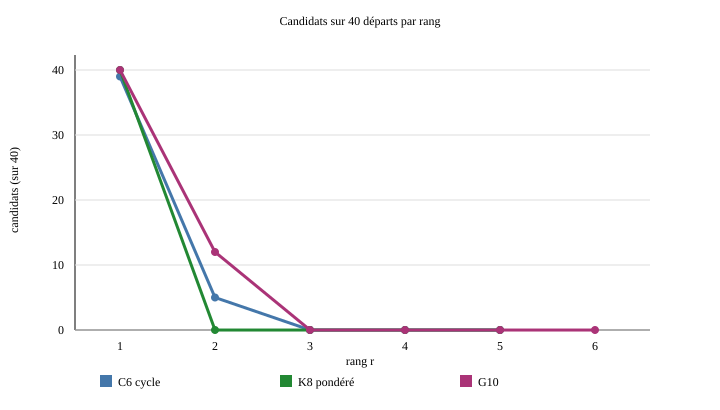

Candidats par rang ; au rang 1 le test tangent est vide.


In [8]:
// Le diagramme utilise les nombres de candidats calculés, avec un axe commun sur 40 départs.
// Le MIME SVG explicite rend la figure consultable dans les lecteurs statiques.
record Svg(string Content);
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Svg>((value, context) =>
{
    context.Writer.Write(value.Content);
    return true;
}, "image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(Svg), new[] { "image/svg+xml" });
var sb = new System.Text.StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='720' height='410' viewBox='0 0 720 410'><rect width='720' height='410' fill='white'/><text x='360' y='25' text-anchor='middle'>Candidats sur 40 départs par rang</text><line x1='75' y1='330' x2='650' y2='330' stroke='black'/><line x1='75' y1='55' x2='75' y2='330' stroke='black'/><text x='18' y='190' transform='rotate(-90 18 190)' text-anchor='middle'>candidats (sur 40)</text>");
for (int t = 0; t <= 40; t += 10)
{
    double y = 330 - 260 * t / 40.0;
    sb.Append($"<line x1='75' y1='{y:F1}' x2='650' y2='{y:F1}' stroke='#ddd'/><text x='64' y='{y + 4:F1}' text-anchor='end'>{t}</text>");
}

string[] couleurs =
{
    "#4477aa",
    "#228833",
    "#aa3377"
};
for (int k = 0; k < 3; k++)
{
    var points = resultats[k].Select(l => (x: 120 + (l.Rang - 1) * 95, y: 330 - 260 * l.Candidats / 40.0)).ToArray();
    sb.Append($"<polyline fill='none' stroke='{couleurs[k]}' stroke-width='3' points='" + string.Join(" ", points.Select(p => $"{p.x},{p.y:F1}")) + "'/>");
    foreach (var p in points)
        sb.Append($"<circle cx='{p.x}' cy='{p.y:F1}' r='4' fill='{couleurs[k]}'/>");
    sb.Append($"<rect x='{100 + k * 180}' y='375' width='12' height='12' fill='{couleurs[k]}'/><text x='{118 + k * 180}' y='386'>{noms[k]}</text>");
}

for (int r = 1; r <= 6; r++)
    sb.Append($"<text x='{120 + (r - 1) * 95}' y='350' text-anchor='middle'>{r}</text>");
sb.Append("<text x='360' y='365' text-anchor='middle'>rang r</text></svg>");
display(new Svg(sb.ToString()));
Console.WriteLine("Candidats par rang ; au rang 1 le test tangent est vide.");


## D. Zoom sur G10 au rang 2

Reprenons les 40 graines d'origine. Si un candidat existe, le plus bas est soumis à 200 perturbations de rayon 0,02 ; sinon le carnet indique explicitement qu'il n'y a pas de zoom disponible, sans changer de graphe.

Avant de lancer le zoom, précisons ce que « le plus bas » veut dire ici. À la section C, le tableau du rang 2 recense 12 candidats sur G10 : des points rendus stationnaires par l'ascension projetée, dont la valeur est strictement inférieure à la référence SDP numérique et qui ont résisté à 20 perturbations d'essai. La cellule suivante rejoue les 40 ascensions (graines 1000+s), applique ces trois portes, puis ne retient qu'un seul candidat : celui de plus faible valeur, donc le plus éloigné de la référence SDP — l'exemplaire le plus net du minimum fallacieux que cette section cherche à isoler.

La sortie committée identifie ce candidat : graine 1038, valeur 13,7699, pour une référence SDP numérique de 14,3249 — un déficit de 0,5551, soit environ 3,9 % de la valeur SDP. Le gradient affiché, 9.98E-008, est plus de trois ordres de grandeur sous la porte de stationnarité de 2e-4 : le point n'est pas « presque » stationnaire, il l'est au sens de la machine. La seconde ligne porte le test de contrainte : 200 perturbations de rayon 0,02, et l'amélioration maximale mesurée est -4.80E-004 — négative. Aucune des 200 directions tirées n'améliore le point (positives : 0) ; la meilleure des perturbations le dégrade encore de près de cinq dix-millièmes.

Ce que ce zoom ne montre pas : il n'examine qu'un seul candidat des 12 du tableau, choisi par une règle de valeur minimale qui ignore leur géométrie ; les directions testées sont tirées au hasard (graine 31415) à rayon fixe ; et la ligne de sortie le rappelle elle-même — aucun certificat de maximum local. La lecture complète de cette limite suit la cellule.

In [9]:
// Le zoom choisit le candidat de plus faible valeur au rang deux puis teste 200 perturbations.
// Une absence d’amélioration sur cet échantillon ne prouve pas un maximum local.
double[, ] choisi = null;
double valeurChoisie = double.PositiveInfinity;
int graineChoisie = -1;
double normeChoisie = 0;
for (int s = 0; s < 40; s++)
{
    var(x, v, g, _) = Ascension(instances[2], 2, 1000 + s);
    if (g < 2e-4 && v < refs[2] - 1e-3 * Math.Max(1, Math.Abs(refs[2])) && Ameliorations(instances[2], x, 20, .02, 9000 + s).All(a => a <= 1e-9) && v < valeurChoisie)
    {
        choisi = x;
        valeurChoisie = v;
        graineChoisie = 1000 + s;
        normeChoisie = g;
    }
}

if (choisi is null)
    Console.WriteLine("Aucun candidat au zoom pour les 40 départs de G10.");
else
{
    var a = Ameliorations(instances[2], choisi, 200, .02, 31415);
    Console.WriteLine($"Graine {graineChoisie} : valeur {valeurChoisie:F4}, SDP numérique {refs[2]:F4}, déficit {refs[2] - valeurChoisie:F4}, gradient {normeChoisie:E2}");
    Console.WriteLine($"200 perturbations : amélioration maximale {a.Max():E2}, positives {a.Count(v => v > 1e-9)} ; aucun certificat de maximum local.");
}


Graine 1038 : valeur 13.7699, SDP numérique 14.3249, déficit 0.5551, gradient 9.98E-008


200 perturbations : amélioration maximale -4.80E-004, positives 0 ; aucun certificat de maximum local.


### Lecture du zoom

Les 200 échantillons donnent une information locale limitée aux directions tirées. Même sans amélioration observée, ils ne démontrent ni la négativité de la hessienne ni l'absence de meilleur voisin.

### Exercice 3 — Effet du rayon

Pour chaque rayon demandé, retournez la meilleure amélioration sur $K$ perturbations. La garde vérifie les clés, les valeurs finies et deux fixtures. Quand le zoom est disponible, le parcours applique les quatre rayons $0{,}005$, $0{,}02$, $0{,}05$, $0{,}1$. Le candidat affiché pour G10 a une valeur de 13,7699 et un déficit de 0,5551 par rapport à la référence numérique.

In [10]:
Dictionary<double, double> Rayon(double[, ] w, double[, ] x, double[] eps, int K, int seed)
{
    return null;
} // TODO : maximum de Ameliorations pour chaque rayon

bool VerifierRayon(Dictionary<double, double> r, double[, ] w, double[, ] x, double[] eps, int K, int seed)
{
    if (r is null)
        return false;
    if (r.Count != eps.Length || eps.Any(e => !r.ContainsKey(e)))
        throw new Exception("Rayons manquants");
    foreach (double e in eps)
    {
        double attendu = Ameliorations(w, x, K, e, seed).Max();
        if (!double.IsFinite(r[e]) || Math.Abs(r[e] - attendu) > 1e-9)
            throw new Exception("Amélioration incorrecte");
    }

    return true;
}

var epsTest = new[]
{
    .01,
    .05
};
var xt1 = Ascension(instances[0], 2, 1001).x;
var xt2 = Ascension(instances[1], 2, 1002).x;
var r1 = Rayon(instances[0], xt1, epsTest, 7, 91);
var r2 = Rayon(instances[1], xt2, epsTest, 9, 92);
bool ok1 = VerifierRayon(r1, instances[0], xt1, epsTest, 7, 91), ok2 = VerifierRayon(r2, instances[1], xt2, epsTest, 9, 92);
if (ok1 != ok2)
    throw new Exception("Réponses partielles pour les rayons");
if (!(ok1 && ok2))
    Console.WriteLine("Exercice 3 à compléter : rayons");
else if (choisi is null)
    Console.WriteLine("Aucun candidat : expérience de rayons indisponible.");
else
{
    var eps = new[]
    {
        .005,
        .02,
        .05,
        .1
    };
    var rep = Rayon(instances[2], choisi, eps, 100, 2718);
    if (VerifierRayon(rep, instances[2], choisi, eps, 100, 2718))
        foreach (double e in eps)
            Console.WriteLine($"ε={e:F3} : amélioration maximale {rep[e]:E3}");
    else
        throw new Exception("Réponse manquante sur le zoom");
}


Exercice 3 à compléter : rayons


## E. Limites et exercices

Les trois exercices répartis portent sur Petersen, la synchronisation bruitée et les rayons de perturbation. L'énumération exacte des coupes est limitée ici à de petits graphes ; CLARABEL reste numérique. Le passage d'une solution SDP à une coupe par arrondi hyperplan est un autre problème.

## À retenir

- La relaxation SDP peut dépasser la meilleure coupe ; sa valeur calculée ici est numérique.
- L'ascension factorisée peut s'arrêter sous cette référence. Au rang 1 les signes restent ceux du départ.
- Des perturbations finies ne certifient pas un maximum local ; les hypothèses des théorèmes de paysage ne sont pas établies pour ces instances.

## Vérifiez votre compréhension

1. Pourquoi la relaxation peut-elle dépasser MaxCut ?

<details><summary>Réponse</summary>
Elle autorise des produits scalaires de vecteurs unitaires, un ensemble plus large que les seules étiquettes $\pm1$.
</details>

2. Pourquoi le rang 1 n'est-il pas une recherche locale par bascules ?

<details><summary>Réponse</summary>
Les lignes vivent sur $S^0$ et le gradient tangent est nul : l'algorithme garde ses signes initiaux.
</details>

3. Que prouvent 200 perturbations sans amélioration ?

<details><summary>Réponse</summary>
Elles ne montrent qu'une absence d'amélioration dans l'échantillon tiré, sans certificat de maximum local.
</details>

## Pour aller plus loin

[Search-09c — discrépance](Search-09c-CombinatorialDiscrepancy.ipynb) ; Burer–Monteiro (2005), [DOI](https://doi.org/10.1007/s10107-004-0564-1) ; [Low-Rank Univariate Sum of Squares](https://doi.org/10.1137/22M1516208) ; [CVXPY](https://www.cvxpy.org/) et [CLARABEL](https://clarabel.org/).